# Classificador PPI, split protein disjoint

Terceira versão do classificador de interação proteína proteína. O benchmark humano completo (split oficial do D-SCRIPT) já rodou e deu AUROC 0.9586 e AUPR 0.796, resultado ótimo, mas medido num split que mistura proteína entre treino e teste, então parte desse número pode vir de o modelo já ter visto aquela proteína antes, em outro par, não de generalização de verdade.

Esse notebook corrige isso. Em vez de usar o split oficial de pares, juntamos todos os pares (treino mais teste do D-SCRIPT) numa pilha só e refazemos o split por conta própria, separando proteínas inteiras entre treino, validação e teste antes de formar os pares. Nenhuma proteína do teste aparece em nenhum par de treino ou validação. Isso deve fazer as métricas caírem em relação à rodada anterior, e é esperado, um número mais baixo aqui é mais honesto que um número mais alto no split anterior.

A arquitetura continua a mesma (ESM2 pequeno congelado mais MLP em cima da diferença e do produto dos embeddings), só a forma de separar os dados muda. No Colab, selecione GPU (T4 já serve) antes de rodar as células de cima pra baixo.

In [ ]:
# Instalação de dependências
!pip install -q transformers tqdm

## Configuração

In [ ]:
import torch

TRAIN_PROTEIN_FRACTION = 0.8  # fração das proteínas alocada pro treino
VAL_PROTEIN_FRACTION = 0.1  # fração pra validação, o resto vai pro teste
MAX_SEQ_LEN = 1000
ESM_MODEL_NAME = "facebook/esm2_t12_35M_UR50D"
EMBED_BATCH_SIZE = 16
TRAIN_BATCH_SIZE = 256
RANDOM_SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo", DEVICE)
if DEVICE.type != "cuda":
    print("Aviso, sem GPU disponível. Em Ambiente de execução > Alterar tipo de ambiente de execução, selecione GPU.")

torch.manual_seed(RANDOM_SEED)

Usando dispositivo cuda


## Baixando os dados

Mesmas fontes do benchmark humano, sequências e os dois arquivos de pares. Mas aqui os dois arquivos de pares vão ser juntados numa pilha só antes de qualquer split, porque quem decide treino, validação e teste agora somos nós, pela proteína, não o arquivo de origem.

In [ ]:
import os, urllib.request

os.makedirs("data", exist_ok=True)

BASE_URL = "https://raw.githubusercontent.com/samsledje/D-SCRIPT/main/data"
FASTA_URL = f"{BASE_URL}/seqs/human.fasta"
TRAIN_PAIRS_URL = f"{BASE_URL}/pairs/human_train.tsv"
TEST_PAIRS_URL = f"{BASE_URL}/pairs/human_test.tsv"

fasta_path = "data/human.fasta"
train_pairs_path = "data/human_train.tsv"
test_pairs_path = "data/human_test.tsv"

for url, path in [(FASTA_URL, fasta_path), (TRAIN_PAIRS_URL, train_pairs_path), (TEST_PAIRS_URL, test_pairs_path)]:
    if not os.path.exists(path):
        print("Baixando", url)
        urllib.request.urlretrieve(url, path)
    else:
        print("Já baixado", path)

print("Pronto.")

Baixando https://raw.githubusercontent.com/samsledje/D-SCRIPT/main/data/seqs/human.fasta
Baixando https://raw.githubusercontent.com/samsledje/D-SCRIPT/main/data/pairs/human_train.tsv
Baixando https://raw.githubusercontent.com/samsledje/D-SCRIPT/main/data/pairs/human_test.tsv
Pronto.


## Lendo sequências e juntando todos os pares numa pilha só

In [ ]:
import pandas as pd

def read_fasta(path):
    seqs = {}
    header = None
    chunks = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if header is not None:
                    seqs[header] = "".join(chunks)
                header = line[1:].split()[0]
                chunks = []
            else:
                chunks.append(line)
        if header is not None:
            seqs[header] = "".join(chunks)
    return seqs

def read_pairs(path, sequences):
    df = pd.read_csv(path, sep="\t", header=None, names=["protein1", "protein2", "label"])
    df["label"] = df["label"].astype(float).astype(int)
    mask = df["protein1"].isin(sequences) & df["protein2"].isin(sequences)
    return df[mask].reset_index(drop=True)

sequences = read_fasta(fasta_path)
print("Proteínas no fasta", len(sequences))

all_pairs = pd.concat([
    read_pairs(train_pairs_path, sequences),
    read_pairs(test_pairs_path, sequences),
], ignore_index=True).drop_duplicates(subset=["protein1", "protein2"]).reset_index(drop=True)

print("Pares totais depois de juntar treino e teste originais", len(all_pairs))
print(all_pairs["label"].value_counts())

Proteínas no fasta 70529
Pares totais depois de juntar treino e teste originais 474517
label
0    431379
1     43138
Name: count, dtype: int64


## Separando as proteínas primeiro, os pares depois

Primeiro sorteamos que proteína vai pra qual grupo (treino, validação ou teste), sem olhar pros pares ainda. Só depois disso um par entra numa lista, e só entra se as duas proteínas do par forem do mesmo grupo. Um par cujas duas proteínas caem em grupos diferentes é descartado, ele não pode representar honestamente nem treino nem avaliação. Isso derruba a quantidade de pares utilizáveis, mas é o preço de uma avaliação que não vaza informação de teste pro treino.

In [1]:
import random

all_proteins = sorted(set(all_pairs["protein1"]) | set(all_pairs["protein2"]))
rng = random.Random(RANDOM_SEED)
shuffled = all_proteins[:]
rng.shuffle(shuffled)

n_total = len(shuffled)
n_train = int(n_total * TRAIN_PROTEIN_FRACTION)
n_val = int(n_total * VAL_PROTEIN_FRACTION)

train_proteins = set(shuffled[:n_train])
val_proteins = set(shuffled[n_train:n_train + n_val])
test_proteins = set(shuffled[n_train + n_val:])

print("Proteínas totais", n_total)
print("Proteínas treino", len(train_proteins), "validação", len(val_proteins), "teste", len(test_proteins))

def filter_pairs_by_protein_group(df, group):
    mask = df["protein1"].isin(group) & df["protein2"].isin(group)
    return df[mask].reset_index(drop=True)

train_df = filter_pairs_by_protein_group(all_pairs, train_proteins)
val_df = filter_pairs_by_protein_group(all_pairs, val_proteins)
test_df = filter_pairs_by_protein_group(all_pairs, test_proteins)

kept = len(train_df) + len(val_df) + len(test_df)
print()
print("Pares de treino", len(train_df))
print("Pares de validação", len(val_df))
print("Pares de teste", len(test_df))
print(f"Pares mantidos no total, {kept} de {len(all_pairs)} ({100*kept/len(all_pairs):.1f}%), o resto cruzava grupos diferentes e foi descartado")
print()
print("Balanço de classes, treino")
print(train_df["label"].value_counts(normalize=True).round(3))
print("Balanço de classes, teste")
print(test_df["label"].value_counts(normalize=True).round(3))

## Conferindo que o split é mesmo protein disjoint

Essa célula devia dar zero. Se der zero, nenhuma proteína do teste apareceu em nenhum par de treino ou de validação, a avaliação que vem mais abaixo mede generalização pra proteína nova de verdade, não pra par novo de proteína já vista, como no benchmark anterior.

In [ ]:
proteins_in_train_pairs = set(train_df["protein1"]) | set(train_df["protein2"])
proteins_in_val_pairs = set(val_df["protein1"]) | set(val_df["protein2"])
proteins_in_test_pairs = set(test_df["protein1"]) | set(test_df["protein2"])

overlap_train_test = proteins_in_train_pairs & proteins_in_test_pairs
overlap_val_test = proteins_in_val_pairs & proteins_in_test_pairs

print("Proteínas em comum entre treino e teste", len(overlap_train_test))
print("Proteínas em comum entre validação e teste", len(overlap_val_test))
assert len(overlap_train_test) == 0 and len(overlap_val_test) == 0, "Split vazou proteína entre grupos, tem bug"
print("Confirmado, split protein disjoint de verdade.")

Proteínas em comum entre treino e teste 0
Proteínas em comum entre validação e teste 0
Confirmado, split protein disjoint de verdade.


## Carregando o ESM2

Mesmo modelo pequeno das versões anteriores, congelado, só extraindo representações.

In [ ]:
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained(ESM_MODEL_NAME)
esm_model = AutoModel.from_pretrained(ESM_MODEL_NAME).to(DEVICE)
esm_model.eval()
for p in esm_model.parameters():
    p.requires_grad = False

EMBED_DIM = esm_model.config.hidden_size
print("Modelo carregado, dimensão do embedding", EMBED_DIM)

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t12_35M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo carregado, dimensão do embedding 480


In [ ]:
from tqdm.auto import tqdm

@torch.no_grad()
def embed_sequences(seq_list, batch_size=EMBED_BATCH_SIZE):
    all_embeds = []
    for i in tqdm(range(0, len(seq_list), batch_size), desc="Gerando embeddings"):
        batch = [s[:MAX_SEQ_LEN] for s in seq_list[i:i + batch_size]]
        tokens = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=MAX_SEQ_LEN + 2)
        tokens = {k: v.to(DEVICE) for k, v in tokens.items()}
        out = esm_model(**tokens)
        hidden = out.last_hidden_state  # (batch, seq_len, dim)
        attn = tokens["attention_mask"]

        # média só sobre os aminoácidos de verdade, exclui padding e os tokens especiais
        # de início (posição 0) e fim (última posição válida de cada sequência)
        seq_lens = attn.sum(dim=1)
        mask = attn.clone().float()
        mask[:, 0] = 0
        last_idx = torch.clamp(seq_lens - 1, min=0)
        mask[torch.arange(mask.size(0)), last_idx] = 0
        mask = mask.unsqueeze(-1)

        lengths = torch.clamp(mask.sum(dim=1), min=1)
        summed = (hidden * mask).sum(dim=1)
        mean_pooled = summed / lengths
        all_embeds.append(mean_pooled.cpu())
    return torch.cat(all_embeds, dim=0)

unique_proteins = sorted(proteins_in_train_pairs | proteins_in_val_pairs | proteins_in_test_pairs)
unique_seqs = [sequences[p] for p in unique_proteins]

print("Calculando embeddings para", len(unique_proteins), "proteínas únicas")
protein_embeddings = embed_sequences(unique_seqs)

embedding_lookup = {pid: protein_embeddings[i] for i, pid in enumerate(unique_proteins)}
print("Embeddings prontos.")

Calculando embeddings para 15725 proteínas únicas


Embeddings prontos.


## Montando as features dos pares

In [ ]:
def build_features(df):
    e1 = torch.stack([embedding_lookup[p] for p in df["protein1"]])
    e2 = torch.stack([embedding_lookup[p] for p in df["protein2"]])
    diff = torch.abs(e1 - e2)
    prod = e1 * e2
    features = torch.cat([diff, prod], dim=1)
    labels = torch.tensor(df["label"].values, dtype=torch.float32)
    return features, labels

X_train, y_train = build_features(train_df)
X_val, y_val = build_features(val_df)
X_test, y_test = build_features(test_df)

print("Formato das features de treino", X_train.shape)

Formato das features de treino torch.Size([306059, 960])


## Classificador

In [ ]:
import torch.nn as nn

class PPIClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

model = PPIClassifier(input_dim=X_train.shape[1]).to(DEVICE)

pos_weight = torch.tensor([(y_train == 0).sum().item() / max((y_train == 1).sum().item(), 1)], device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

print("Peso da classe positiva na perda", pos_weight.item())

Peso da classe positiva na perda 9.495850563049316


## Treinando

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import copy

def to_loader(X, y, batch_size, shuffle):
    dataset = torch.utils.data.TensorDataset(X, y)
    return torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = to_loader(X_train, y_train, TRAIN_BATCH_SIZE, shuffle=True)

EPOCHS = 30
PATIENCE = 5
best_val_aupr = -1
best_state = None
epochs_sem_melhora = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    train_loss = total_loss / len(X_train)

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val.to(DEVICE)).cpu()
        val_probs = torch.sigmoid(val_logits).numpy()
        val_auroc = roc_auc_score(y_val, val_probs)
        val_aupr = average_precision_score(y_val, val_probs)

    print(f"Época {epoch:02d} perda treino {train_loss:.4f} AUROC val {val_auroc:.4f} AUPR val {val_aupr:.4f}")

    if val_aupr > best_val_aupr:
        best_val_aupr = val_aupr
        best_state = copy.deepcopy(model.state_dict())
        epochs_sem_melhora = 0
    else:
        epochs_sem_melhora += 1
        if epochs_sem_melhora >= PATIENCE:
            print("Sem melhora na validação por", PATIENCE, "épocas, parando.")
            break

model.load_state_dict(best_state)
print("Melhor AUPR de validação", round(best_val_aupr, 4))

## Avaliação final no teste

Esse número é o que realmente importa comparar com a rodada anterior. Se cair em relação ao AUROC 0.9586 e AUPR 0.796 do split oficial, isso confirma que parte daquele resultado vinha de proteína repetida entre treino e teste, não de generalização de verdade. Um valor mais baixo aqui não é uma piora do modelo, é uma medida mais honesta do que ele realmente sabe fazer.

AUROC teste (protein disjoint) 0.9137
AUPR teste (protein disjoint) 0.6214

              precision    recall  f1-score   support

não interage       0.98      0.91      0.94      4311
    interage       0.38      0.75      0.51       326

    accuracy                           0.90      4637
   macro avg       0.68      0.83      0.72      4637
weighted avg       0.94      0.90      0.91      4637



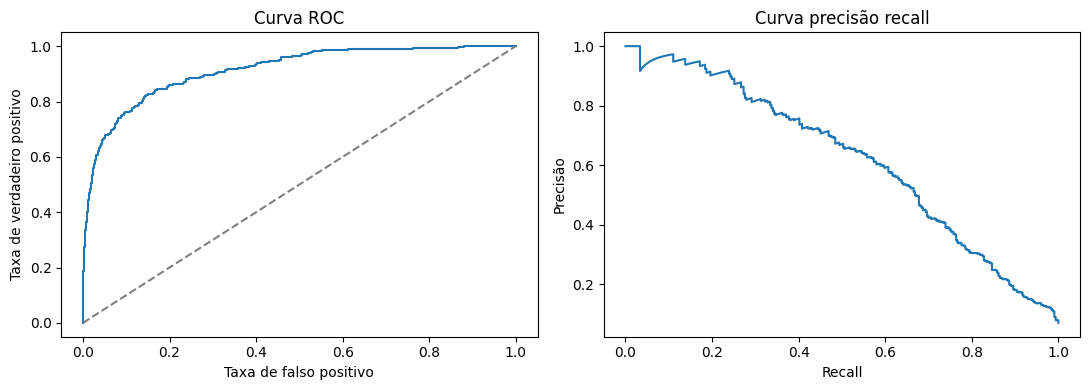

In [ ]:
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    test_logits = model(X_test.to(DEVICE)).cpu()
    test_probs = torch.sigmoid(test_logits).numpy()

test_auroc = roc_auc_score(y_test, test_probs)
test_aupr = average_precision_score(y_test, test_probs)
print("AUROC teste (protein disjoint)", round(test_auroc, 4))
print("AUPR teste (protein disjoint)", round(test_aupr, 4))
print()
print(classification_report(y_test, (test_probs >= 0.5).astype(int), target_names=["não interage", "interage"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

fpr, tpr, _ = roc_curve(y_test, test_probs)
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("Curva ROC")
axes[0].set_xlabel("Taxa de falso positivo")
axes[0].set_ylabel("Taxa de verdadeiro positivo")

prec, rec, _ = precision_recall_curve(y_test, test_probs)
axes[1].plot(rec, prec)
axes[1].set_title("Curva precisão recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")

plt.tight_layout()
plt.show()

## Salvando o modelo treinado

In [ ]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "esm_model_name": ESM_MODEL_NAME,
    "embed_dim": EMBED_DIM,
    "max_seq_len": MAX_SEQ_LEN,
    "test_auroc": test_auroc,
    "test_aupr": test_aupr,
    "split": "protein_disjoint",
}
torch.save(checkpoint, "ppi_classifier_protein_disjoint_checkpoint.pt")
print("Checkpoint salvo em ppi_classifier_protein_disjoint_checkpoint.pt")

## Próximos passos

Com essa avaliação mais honesta em mãos, os próximos passos ficam assim, em ordem de esforço

1. Descongelar as últimas camadas do ESM2 e fazer fine tuning de verdade, em vez de só usar como extrator de features fixo. Agora com um número confiável de generalização, dá pra medir se o fine tuning realmente ajuda ou só decora mais ainda.
2. Trocar o ESM2 pequeno por uma versão maior, por exemplo facebook/esm2_t30_150M_UR50D.
3. Trocar o problema de classificação binária por regressão de afinidade de ligação fármaco alvo, usando BindingDB ou PDBbind, esse é o passo que liga o projeto direto a descoberta de medicamento.
4. Escolher um alvo terapêutico específico e montar dados em cima dele, em vez do benchmark genérico.